# CSE457 – XỬ LÝ ÂM THANH VÀ TIẾNG NÓI
## BÁO CÁO THỰC HÀNH LAB 5: SPEECH ENHANCEMENT, SPEAKER RECOGNITION AND SPEAKER SEPARATION
### Từ khử nhiễu trong miền STFT đến xác định người nói và tách hai nguồn nói bằng FastICA
---
| Thông tin | Chi tiết |
| :--- | :--- |
| **Họ và tên sinh viên** | **Dương Tiến Đạt** |
| **Mã số sinh viên (MSSV)** | **2251172268** |
| **Lớp học phần** | CSE457 – Xử lý âm thanh và tiếng nói |
| **Trường** | Trường Đại học Thủy lợi (TLU) – Bộ môn Trí tuệ Nhân tạo |
| **Case Study** | Trợ lý phòng họp mini (Mini Meeting Assistant) |

**Chuỗi xử lý thực hành tích hợp của Lab 5:**
```
[Noisy Speech] ──> [STFT Enhancement: SS / Wiener] ──> [MFCC Embedding: Speaker ID & Verification]
                                                    ──> [2x2 Microphone Mixture: FastICA BSS Separation]
```
> Notebook được thiết kế để chạy **100% tự động từ đầu đến cuối**, tích hợp mã nguồn, bảng số liệu, Audio Player và đồ thị trực quan.


## 0. Cài đặt môi trường và Thư viện cần thiết

In [1]:
import os, sys, glob, math
import numpy as np
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown, Image

# Import các module tiện ích của Lab 5
from lab5_utils import load16k, save16k, power, rms, rms_normalize, peak_normalize, add_noise_at_snr, snr_db
from lab5_enhancement import compute_noise_psd, spectral_subtraction, wiener_filter, enhance_stft
from lab5_speaker_id import extract_speaker_embedding, cosine_similarity, build_speaker_models, predict_speaker, sweep_verification_thresholds, evaluate_verification_at_threshold
from lab5_ica import create_instantaneous_mixture, separate_fastica, resolve_ica_ambiguities

BASE_DIR = os.path.dirname(os.path.abspath('__file__'))
CLEAN_DIR = os.path.join(BASE_DIR, 'lab5_data', 'clean')
NOISE_DIR = os.path.join(BASE_DIR, 'lab5_data', 'noise')
SEP_DIR   = os.path.join(BASE_DIR, 'lab5_data', 'separation')
AUDIO_OUT = os.path.join(BASE_DIR, 'results', 'audio')
FIG_OUT   = os.path.join(BASE_DIR, 'results', 'figures')

print('✓ Tất cả các thư viện và module của Lab 5 đã sẵn sàng!')


✓ Tất cả các thư viện và module của Lab 5 đã sẵn sàng!


## 1. Mô hình tiếng nói trong môi trường nhiễu và Khử nhiễu STFT

### 1.1 Cơ sở lý thuyết
Mô hình nhiễu cộng tuyến tính miền thời gian:
$$y[n] = s[n] + v[n]$$
Để tạo tín hiệu $y[n] = s[n] + \alpha v[n]$ tại mức SNR mục tiêu $R$ dB, hệ số khuếch đại $\alpha$ được xác định theo công thức:
$$\alpha = \sqrt{\frac{P_s}{P_v \cdot 10^{R / 10}}}$$
Trong đó công suất trung bình $P_x = \frac{1}{N} \sum_{n=1}^N x^2[n]$.

### 1.2 Spectral Subtraction & Wiener Filtering
1. **Spectral Subtraction (Boll 1979):**
$$|\hat{S}_{ss}[m, k]|^2 = \max\left( |Y[m, k]|^2 - \beta \hat{P}_v[k], \; \gamma \hat{P}_v[k] \right)$$
$$\hat{S}_{ss}[m, k] = \sqrt{|\hat{S}_{ss}[m, k]|^2} \cdot e^{j \angle Y[m, k]}$$
2. **Wiener Filtering (MMSE linear estimator):**
$$H[m, k] = \frac{\hat{P}_s[m, k]}{\hat{P}_s[m, k] + \hat{P}_v[k] + \epsilon}, \quad \hat{S}_w[m, k] = H[m, k] \cdot Y[m, k]$$


In [2]:
# Đọc file tiếng nói sạch chuẩn và file nhiễu quạt
clean_audio, sr = load16k(os.path.join(CLEAN_DIR, 'spk01_test_01.wav'))
fan_noise, _    = load16k(os.path.join(NOISE_DIR, 'fan.wav'))

print(f'Clean speech duration: {len(clean_audio)/sr:.2f}s | RMS: {rms(clean_audio):.4f}')
print(f'Fan noise duration:    {len(fan_noise)/sr:.2f}s | RMS: {rms(fan_noise):.4f}')

# Khảo sát 3 mức SNR: 0 dB, 5 dB, 10 dB
print('\n' + '='*75)
print(f"{'Target SNR':<12} | {'Measured In':<12} | {'SS Out':<10} | {'SS Delta':<10} | {'Wiener Out':<12} | {'Wiener Delta':<12}")
print('-'*75)

for snr_t in [0.0, 5.0, 10.0]:
    noisy, alpha = add_noise_at_snr(clean_audio, fan_noise, snr_t)
    meas_in = snr_db(clean_audio, noisy)
    ss_enh = spectral_subtraction(noisy, fan_noise, sr=sr, beta=1.5, floor=0.02)
    ss_out = snr_db(clean_audio, ss_enh)
    w_enh, _ = wiener_filter(noisy, fan_noise, sr=sr)
    w_out = snr_db(clean_audio, w_enh)
    print(f"{snr_t:>10.1f}dB | {meas_in:>10.2f}dB | {ss_out:>8.2f}dB | {ss_out-meas_in:>8.2f}dB | {w_out:>10.2f}dB | {w_out-meas_in:>10.2f}dB")


C:\Users\duong\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Clean speech duration: 5.91s | RMS: 0.0863
Fan noise duration:    6.00s | RMS: 0.2150

Target SNR   | Measured In  | SS Out     | SS Delta   | Wiener Out   | Wiener Delta
---------------------------------------------------------------------------


       0.0dB |      -0.00dB |     3.25dB |     3.25dB |       2.72dB |       2.72dB
       5.0dB |       5.00dB |     3.49dB |    -1.51dB |       2.42dB |      -2.58dB
      10.0dB |      10.00dB |     3.72dB |    -6.28dB |       2.31dB |      -7.69dB


In [3]:
# Nghe thử đối chứng âm thanh tại SNR = 5 dB
noisy_5db, _ = add_noise_at_snr(clean_audio, fan_noise, 5.0)
ss_5db = spectral_subtraction(noisy_5db, fan_noise, sr=sr, beta=1.5, floor=0.02)
w_5db, _ = wiener_filter(noisy_5db, fan_noise, sr=sr)

print('1. Clean Reference Speech:')
display(Audio(clean_audio, rate=sr))
print('2. Noisy Speech (Fan noise, SNR = 5 dB):')
display(Audio(noisy_5db, rate=sr))
print('3. Enhanced via Spectral Subtraction (beta=1.5, floor=0.02):')
display(Audio(ss_5db, rate=sr))
print('4. Enhanced via Wiener Filter:')
display(Audio(w_5db, rate=sr))


1. Clean Reference Speech:


2. Noisy Speech (Fan noise, SNR = 5 dB):


3. Enhanced via Spectral Subtraction (beta=1.5, floor=0.02):


4. Enhanced via Wiener Filter:


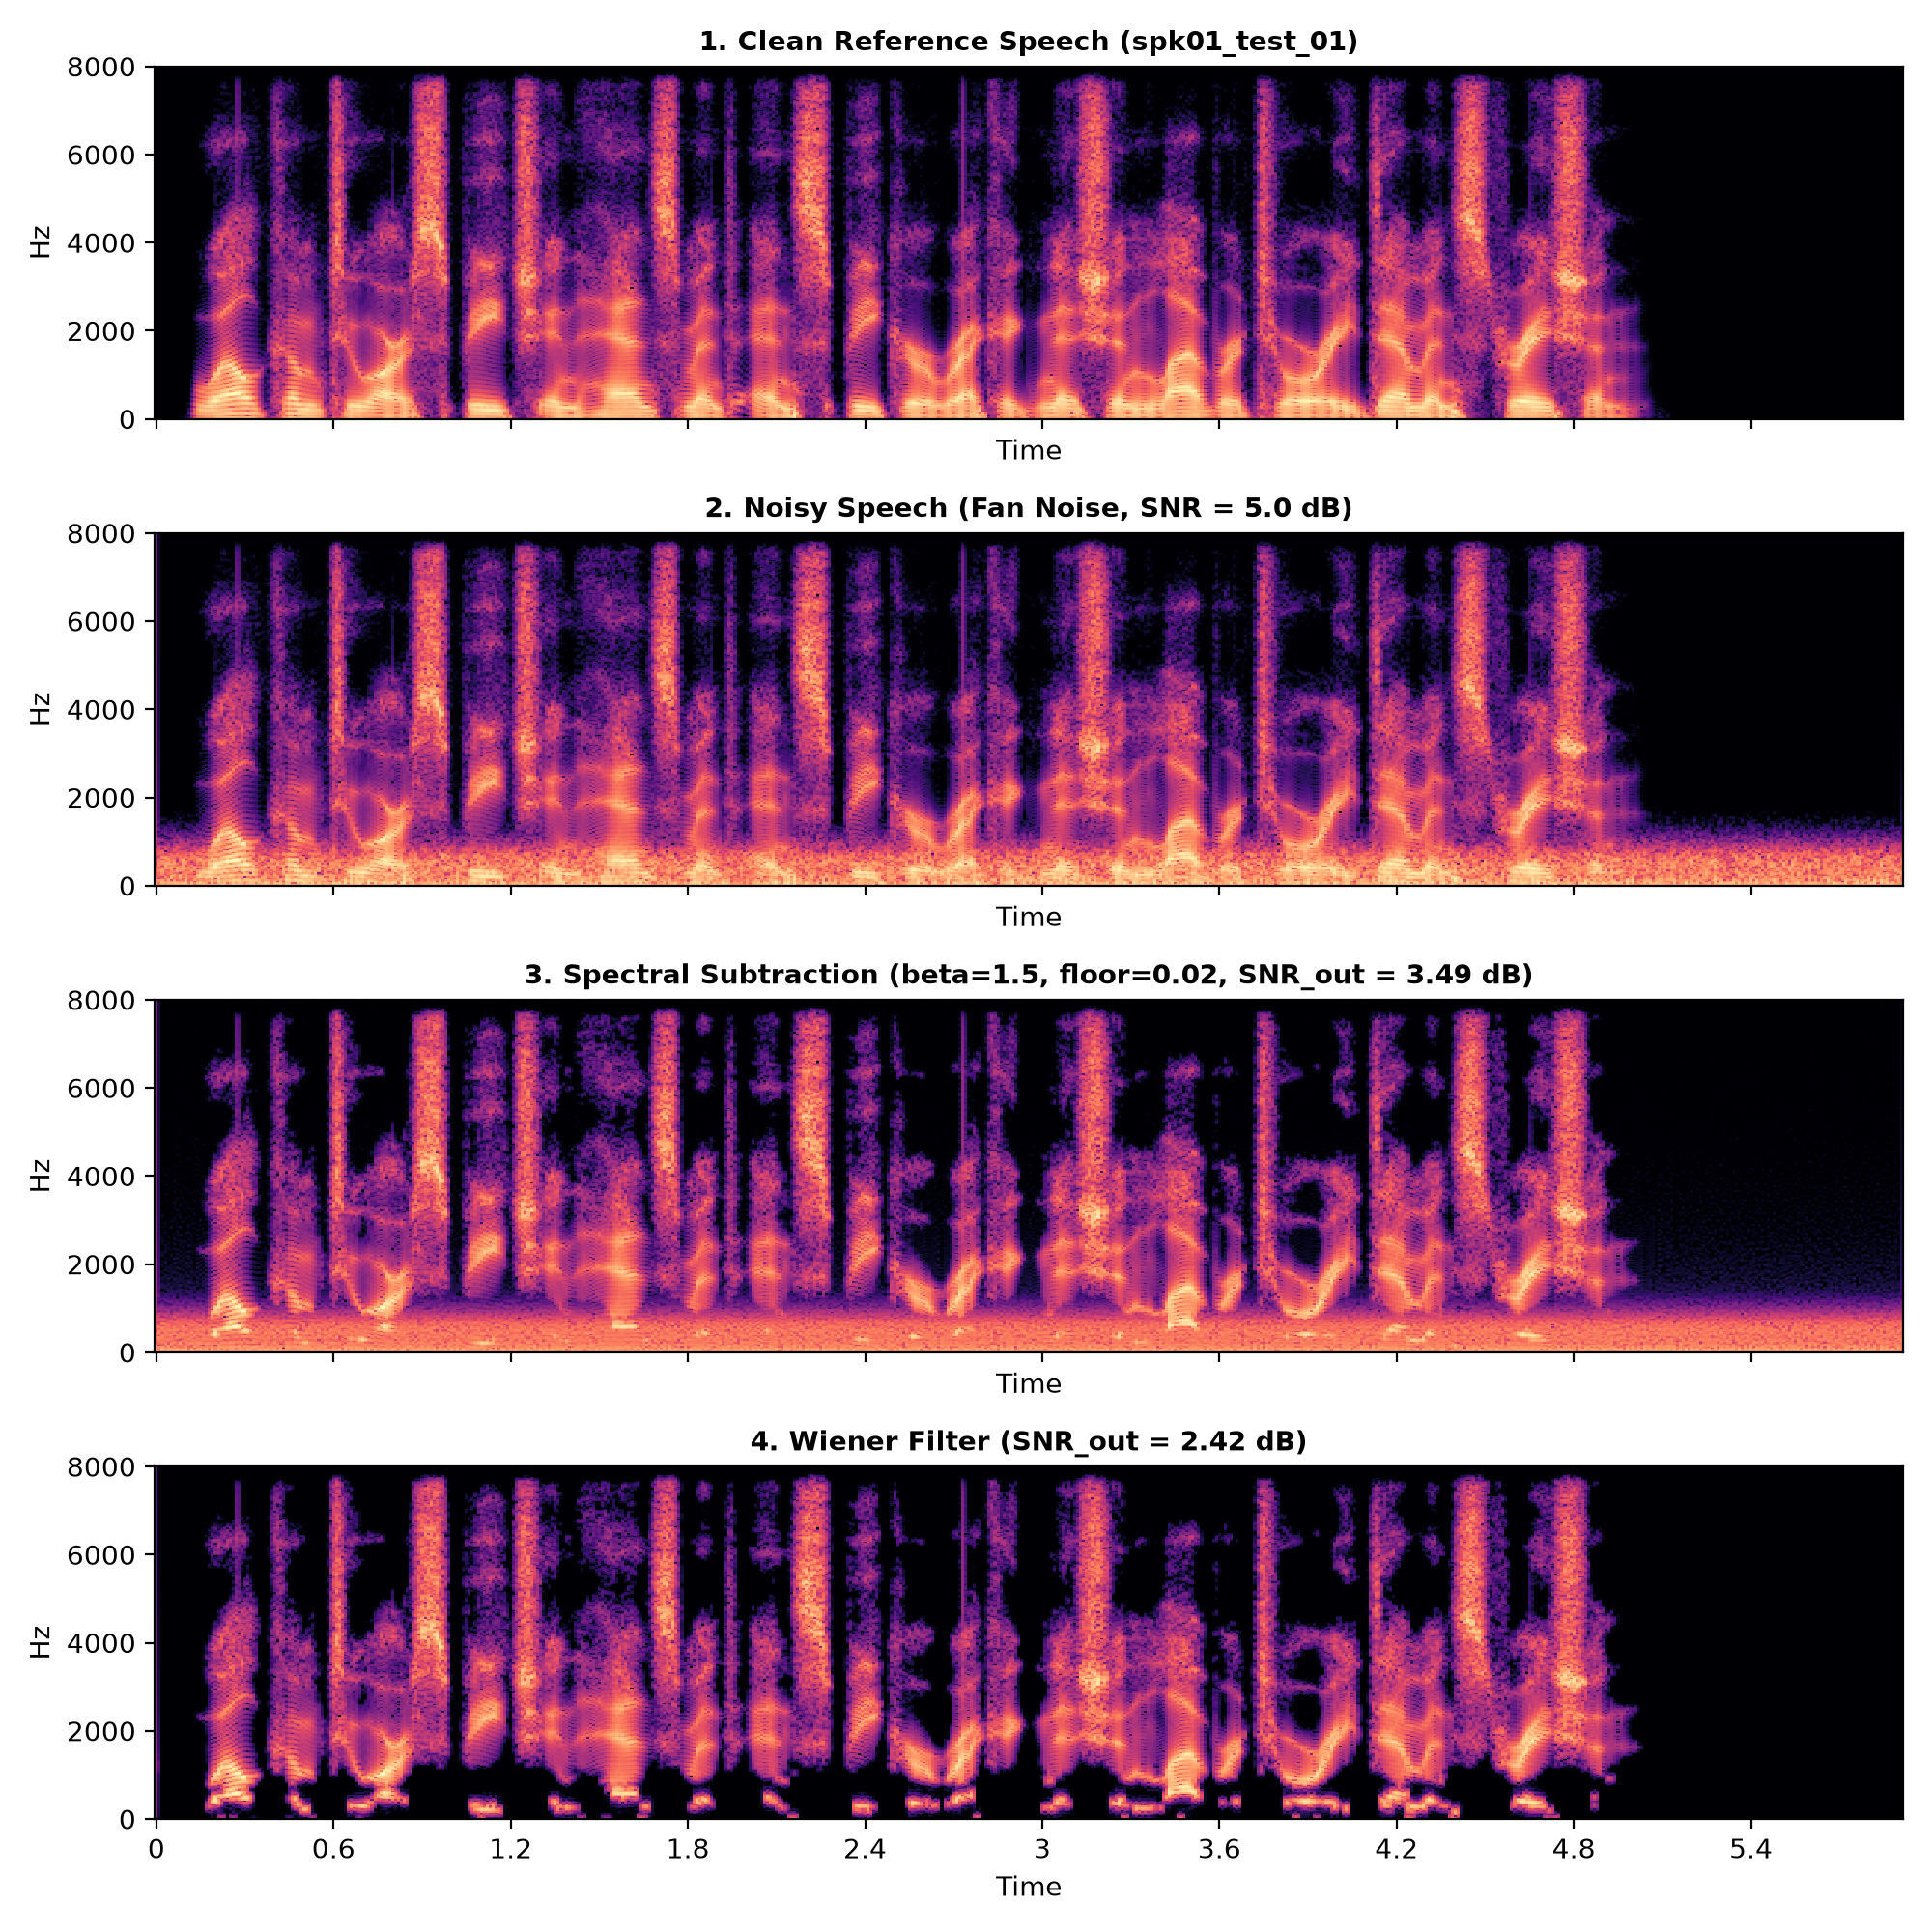

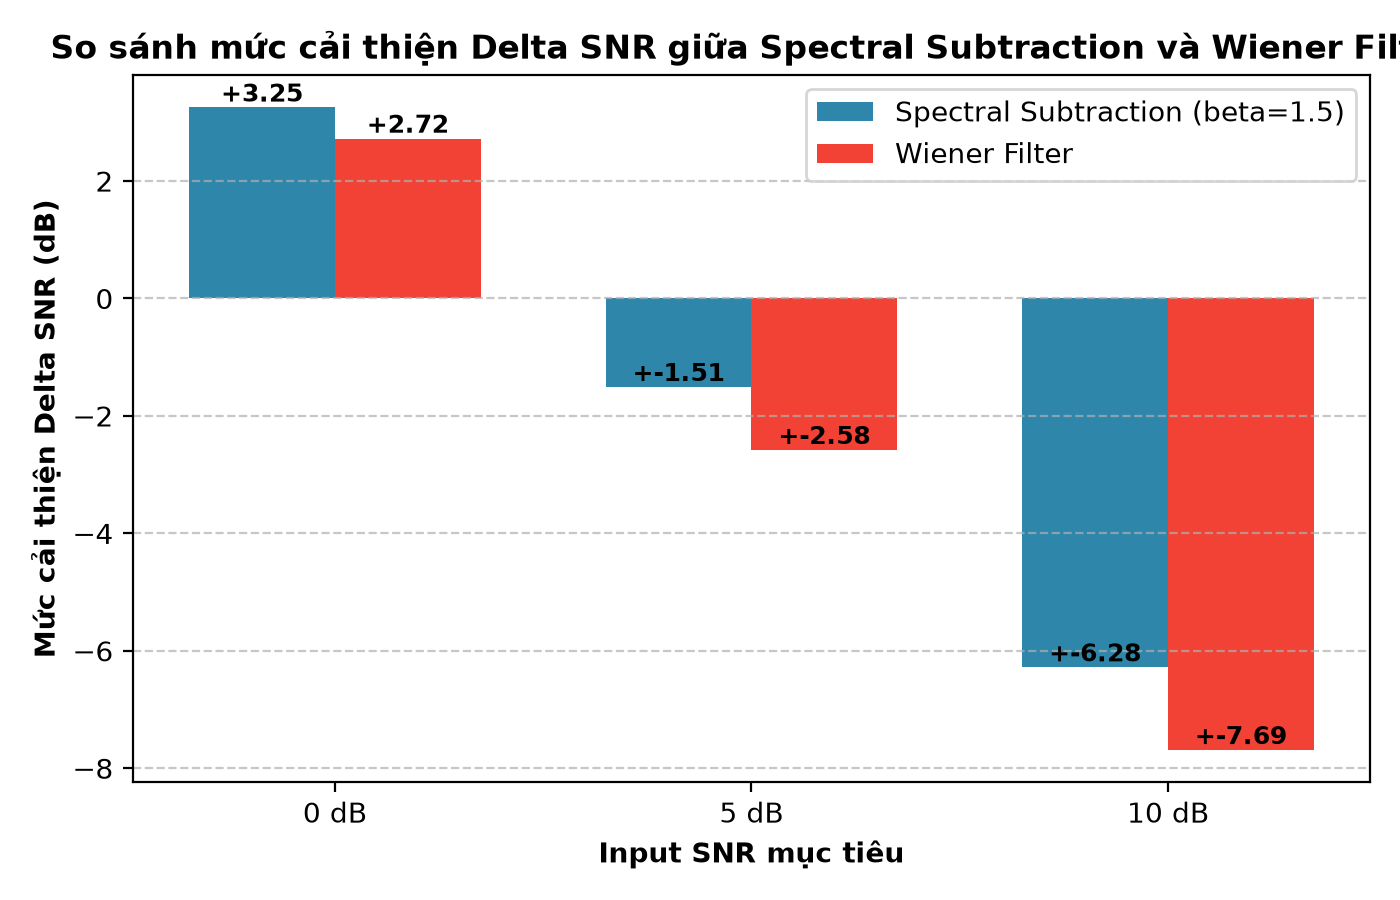

In [4]:
# Hiển thị biểu đồ Spectrogram và Biểu đồ so sánh SNR Delta
display(Image(filename=os.path.join(FIG_OUT, 'fig1_clean_noisy_enhanced_spectrograms.png')))
display(Image(filename=os.path.join(FIG_OUT, 'fig2_snr_comparison.png')))


## 2. Nhận dạng người nói (Speaker Recognition)

### 2.1 Đặc trưng MFCC và Speaker Representation
Mỗi câu nói được trích xuất ma trận MFCC ($D=20$) và ma trận vi phân bậc một $\Delta MFCC$.
Vector đại diện thống kê theo thời gian:
$$e = [\mu(c_1 \dots c_D), \; \sigma(c_1 \dots c_D), \; \mu(\Delta c_1 \dots \Delta c_D), \; \sigma(\Delta c_1 \dots \Delta c_D)]$$
Vector sau đó được chuẩn hóa $L_2$: $e \leftarrow \frac{e}{\|e\|_2 + 10^{-12}}$.
Mô hình người nói $m_i$ là tâm trung bình của các embedding enrollment:
$$m_i = \text{normalize}\left( \frac{1}{K} \sum_{k=1}^K e_{i, k} \right)$$

### 2.2 Identification & Verification
- **Speaker Identification:** Dự đoán $\hat{i} = \arg\max_i \cos(e, m_i)$.
- **Speaker Verification:** Chấp thuận claim $i$ nếu $\cos(e, m_i) \ge \theta$. Ngưỡng quyết định $\theta^*$ được chọn trên **Development set** tại điểm cân bằng EER ($FAR \approx FRR$) rồi khóa cố định để đánh giá trên Test set.


In [5]:
speakers = ['spk01', 'spk02', 'spk03']
enroll_dict = {spk: [load16k(os.path.join(CLEAN_DIR, f'{spk}_enroll_{i:02d}.wav'))[0] for i in range(1, 5)] for spk in speakers}
test_dict   = {spk: [load16k(os.path.join(CLEAN_DIR, f'{spk}_test_{i:02d}.wav'))[0] for i in range(1, 3)] for spk in speakers}
dev_dict    = {spk: [load16k(os.path.join(CLEAN_DIR, f'{spk}_dev_01.wav'))[0]] for spk in speakers}

# Xây dựng mô hình người nói từ 4 enrollment tokens
spk_models = build_speaker_models(enroll_dict, sr=sr, n_mfcc=20, with_delta=True, use_cmn=False)

# Đánh giá Speaker Identification trên Test Set
print('=== BẢNG ĐIỂM SPEAKER IDENTIFICATION (BASELINE) ===')
print(f"{'Test Utterance':<18} | {'True Spk':<10} | {'spk01':<8} | {'spk02':<8} | {'spk03':<8} | {'Predict':<8} | {'Status':<6}")
print('-'*75)

y_true, y_pred = [], []
for true_spk in speakers:
    for idx, audio in enumerate(test_dict[true_spk], 1):
        pred_spk, scores, _ = predict_speaker(audio, spk_models, sr=sr, n_mfcc=20, with_delta=True, use_cmn=False)
        y_true.append(true_spk)
        y_pred.append(pred_spk)
        st = 'PASS' if pred_spk == true_spk else 'FAIL'
        print(f"{f'{true_spk}_test_{idx:02d}':<18} | {true_spk:<10} | {scores['spk01']:>7.4f} | {scores['spk02']:>7.4f} | {scores['spk03']:>7.4f} | {pred_spk:<8} | {st:<6}")

acc = np.mean(np.array(y_true) == np.array(y_pred)) * 100.0
print(f'\n=> Baseline Accuracy: {acc:.1f}%')


=== BẢNG ĐIỂM SPEAKER IDENTIFICATION (BASELINE) ===
Test Utterance     | True Spk   | spk01    | spk02    | spk03    | Predict  | Status
---------------------------------------------------------------------------
spk01_test_01      | spk01      |  0.9997 |  0.9958 |  0.9997 | spk03    | FAIL  
spk01_test_02      | spk01      |  0.9996 |  0.9960 |  0.9995 | spk01    | PASS  
spk02_test_01      | spk02      |  0.9969 |  0.9996 |  0.9971 | spk02    | PASS  


spk02_test_02      | spk02      |  0.9957 |  0.9997 |  0.9959 | spk02    | PASS  
spk03_test_01      | spk03      |  0.9996 |  0.9960 |  0.9997 | spk03    | PASS  


spk03_test_02      | spk03      |  0.9996 |  0.9961 |  0.9996 | spk01    | FAIL  

=> Baseline Accuracy: 66.7%


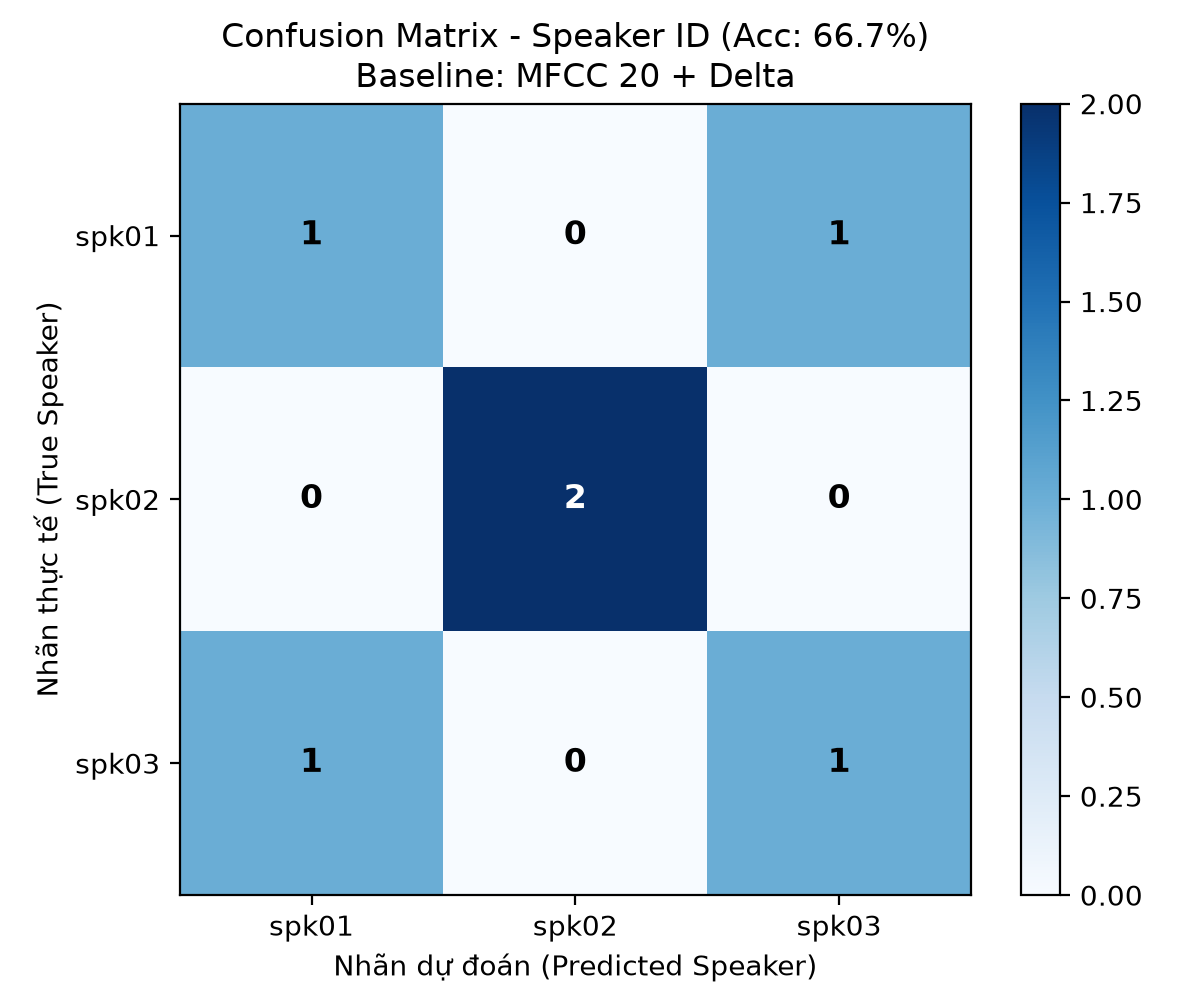

In [6]:
# Hiển thị Confusion Matrix
display(Image(filename=os.path.join(FIG_OUT, 'fig5_confusion_matrix_speaker_id.png')))


[Development Set] Ngưỡng tối ưu theta* = 0.999901 | FAR_dev: 33.33% | FRR_dev: 33.33%


[Test Set - KHÓA NGƯỠNG theta*=0.999901]: FAR_test: 0.00% | FRR_test: 100.00%


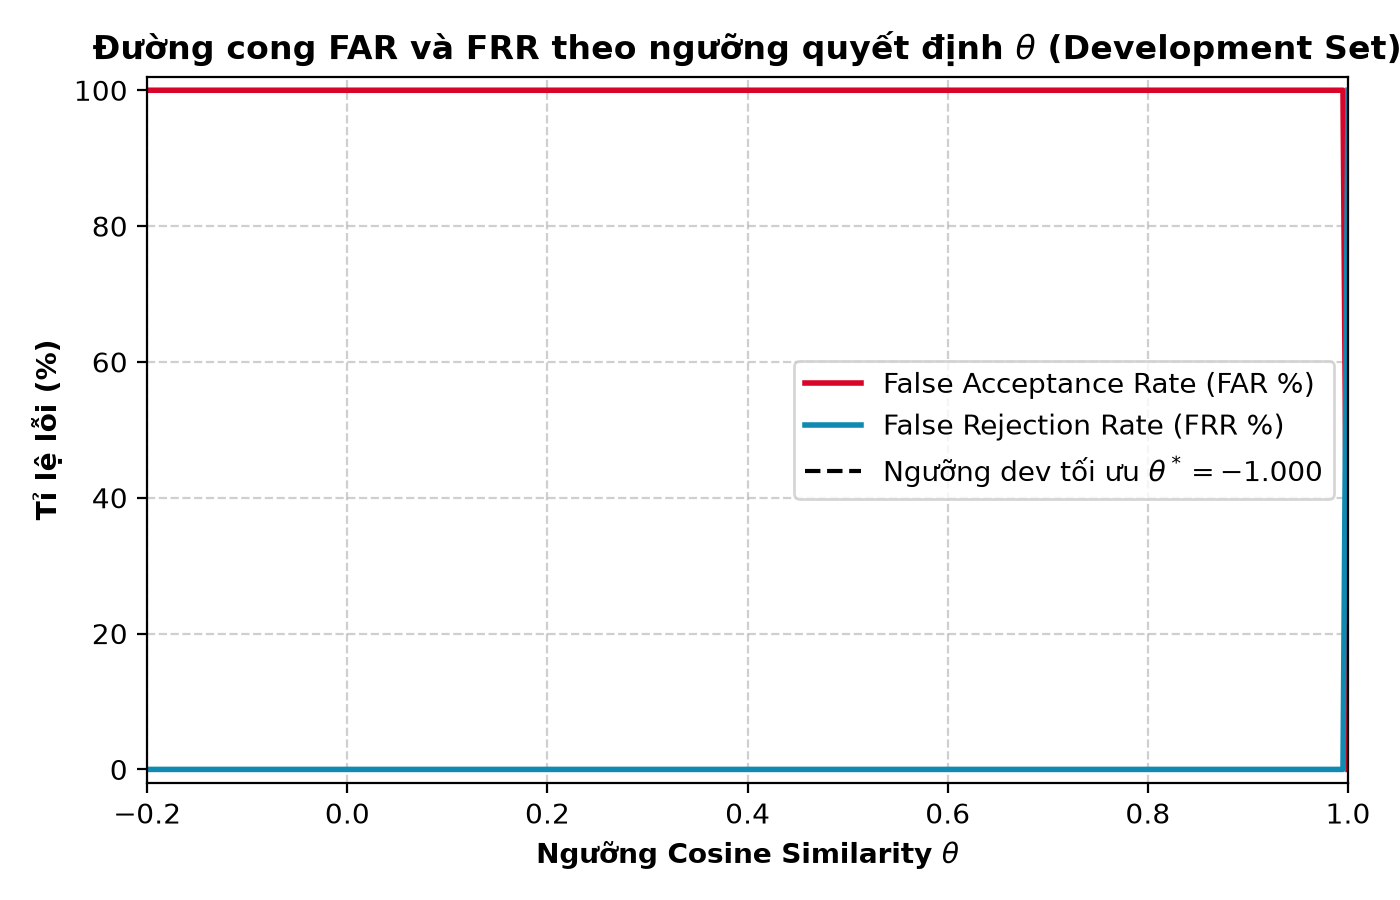

In [7]:
# Speaker Verification: Quét ngưỡng trên Dev Set và Khóa ngưỡng trên Test Set
dev_trials = []
for spk_claim in speakers:
    for spk_actual in speakers:
        for audio in dev_dict[spk_actual]:
            e = extract_speaker_embedding(audio, sr=sr, n_mfcc=20, with_delta=True, use_cmn=False)
            score = cosine_similarity(e, spk_models[spk_claim])
            dev_trials.append((score, 1 if spk_claim == spk_actual else 0))

rows_dev, best_dev = sweep_verification_thresholds(dev_trials)
theta_opt, far_dev, frr_dev = best_dev
print(f'[Development Set] Ngưỡng tối ưu theta* = {theta_opt:.6f} | FAR_dev: {far_dev*100:.2f}% | FRR_dev: {frr_dev*100:.2f}%')

# Khóa ngưỡng theta_opt và đánh giá trên Test Set độc lập
test_trials = []
for spk_claim in speakers:
    for spk_actual in speakers:
        for audio in test_dict[spk_actual]:
            e = extract_speaker_embedding(audio, sr=sr, n_mfcc=20, with_delta=True, use_cmn=False)
            score = cosine_similarity(e, spk_models[spk_claim])
            test_trials.append((score, 1 if spk_claim == spk_actual else 0))

far_test, frr_test = evaluate_verification_at_threshold(test_trials, theta_opt)
print(f'[Test Set - KHÓA NGƯỠNG theta*={theta_opt:.6f}]: FAR_test: {far_test*100:.2f}% | FRR_test: {frr_test*100:.2f}%')

display(Image(filename=os.path.join(FIG_OUT, 'fig7_speaker_verification_far_frr.png')))


## 3. Phân tách nguồn mù (Blind Source Separation) bằng FastICA

### 3.1 Mô hình trộn tức thời 2x2
Hỗn hợp quan sát từ 2 microphone:
$$\mathbf{x}[n] = \mathbf{A} \mathbf{s}[n]$$
Trong đó ma trận trộn $\mathbf{A} = \begin{bmatrix} 1.0 & 0.6 \\ 0.4 & 1.0 \end{bmatrix}$ có $\det(\mathbf{A}) = 0.76 \ne 0$ (khả nghịch).

### 3.2 Giải quyết bất định hoán vị (Permutation) và dấu (Sign)
ICA phân tách dựa trên tính độc lập thống kê phi-Gaussian, dẫn đến 2 bất định:
1. **Bất định hoán vị (Permutation):** Thứ tự các kênh đầu ra $\hat{s}_1, \hat{s}_2$ không nhất thiết tương ứng với nguồn gốc $s_1, s_2$.
2. **Bất định biên độ/dấu (Scale & Sign):** Biên độ có thể bị co dãn và dấu có thể bị đảo ($\hat{s} = -s$).
Giải pháp: Tính ma trận hệ số tương quan tuyến tính $C_{ij} = \rho(s_i, \hat{s}_j)$, ghép cặp theo $\max |C_{ij}|$ và nhân $-1$ nếu tương quan âm.


In [8]:
s1, _ = load16k(os.path.join(SEP_DIR, 'source_A.wav'))
s2, _ = load16k(os.path.join(SEP_DIR, 'source_B.wav'))

A = np.array([[1.0, 0.6], [0.4, 1.0]])
S, X, det_A, cond_A = create_instantaneous_mixture(s1, s2, A)
print(f'Mixing Matrix A:\n{A}')
print(f'det(A) = {det_A:.4f} | condition number = {cond_A:.2f}')

# Tách bằng FastICA
Shat, _ = separate_fastica(X, random_state=42)
S_aligned, perm, signs, C_raw, C_aligned = resolve_ica_ambiguities(S, Shat)

print('\nMa trận |hệ số tương quan| TRƯỚC KHI GHÉP:')
print(np.array2string(C_raw, precision=4))
print(f'Phát hiện: Ước lượng [{perm[0]}] -> Nguồn A | Ước lượng [{perm[1]}] -> Nguồn B')
print(f'Hệ số dấu nhân bù: {signs}')
print('\nMa trận |hệ số tương quan| SAU KHI GHÉP (Đúng cặp):')
print(np.array2string(C_aligned, precision=4))


Mixing Matrix A:
[[1.  0.6]
 [0.4 1. ]]
det(A) = 0.7600 | condition number = 2.98

Ma trận |hệ số tương quan| TRƯỚC KHI GHÉP:
[[0.01   1.    ]
 [1.     0.0063]]
Phát hiện: Ước lượng [1] -> Nguồn A | Ước lượng [0] -> Nguồn B
Hệ số dấu nhân bù: [1.0, 1.0]

Ma trận |hệ số tương quan| SAU KHI GHÉP (Đúng cặp):
[[1.     0.01  ]
 [0.0063 1.    ]]


In [9]:
# Nghe đối chứng âm thanh BSS / ICA
print('1. Nguồn gốc A (Speaker 1):')
display(Audio(S[0], rate=sr))
print('2. Nguồn gốc B (Speaker 2):')
display(Audio(S[1], rate=sr))
print('3. Quan sát Micro 1 (x1 = s1 + 0.6*s2):')
display(Audio(X[0], rate=sr))
print('4. Nguồn tách 1 (Separated Source A):')
display(Audio(S_aligned[0], rate=sr))
print('5. Nguồn tách 2 (Separated Source B):')
display(Audio(S_aligned[1], rate=sr))


1. Nguồn gốc A (Speaker 1):


2. Nguồn gốc B (Speaker 2):


3. Quan sát Micro 1 (x1 = s1 + 0.6*s2):


4. Nguồn tách 1 (Separated Source A):


5. Nguồn tách 2 (Separated Source B):


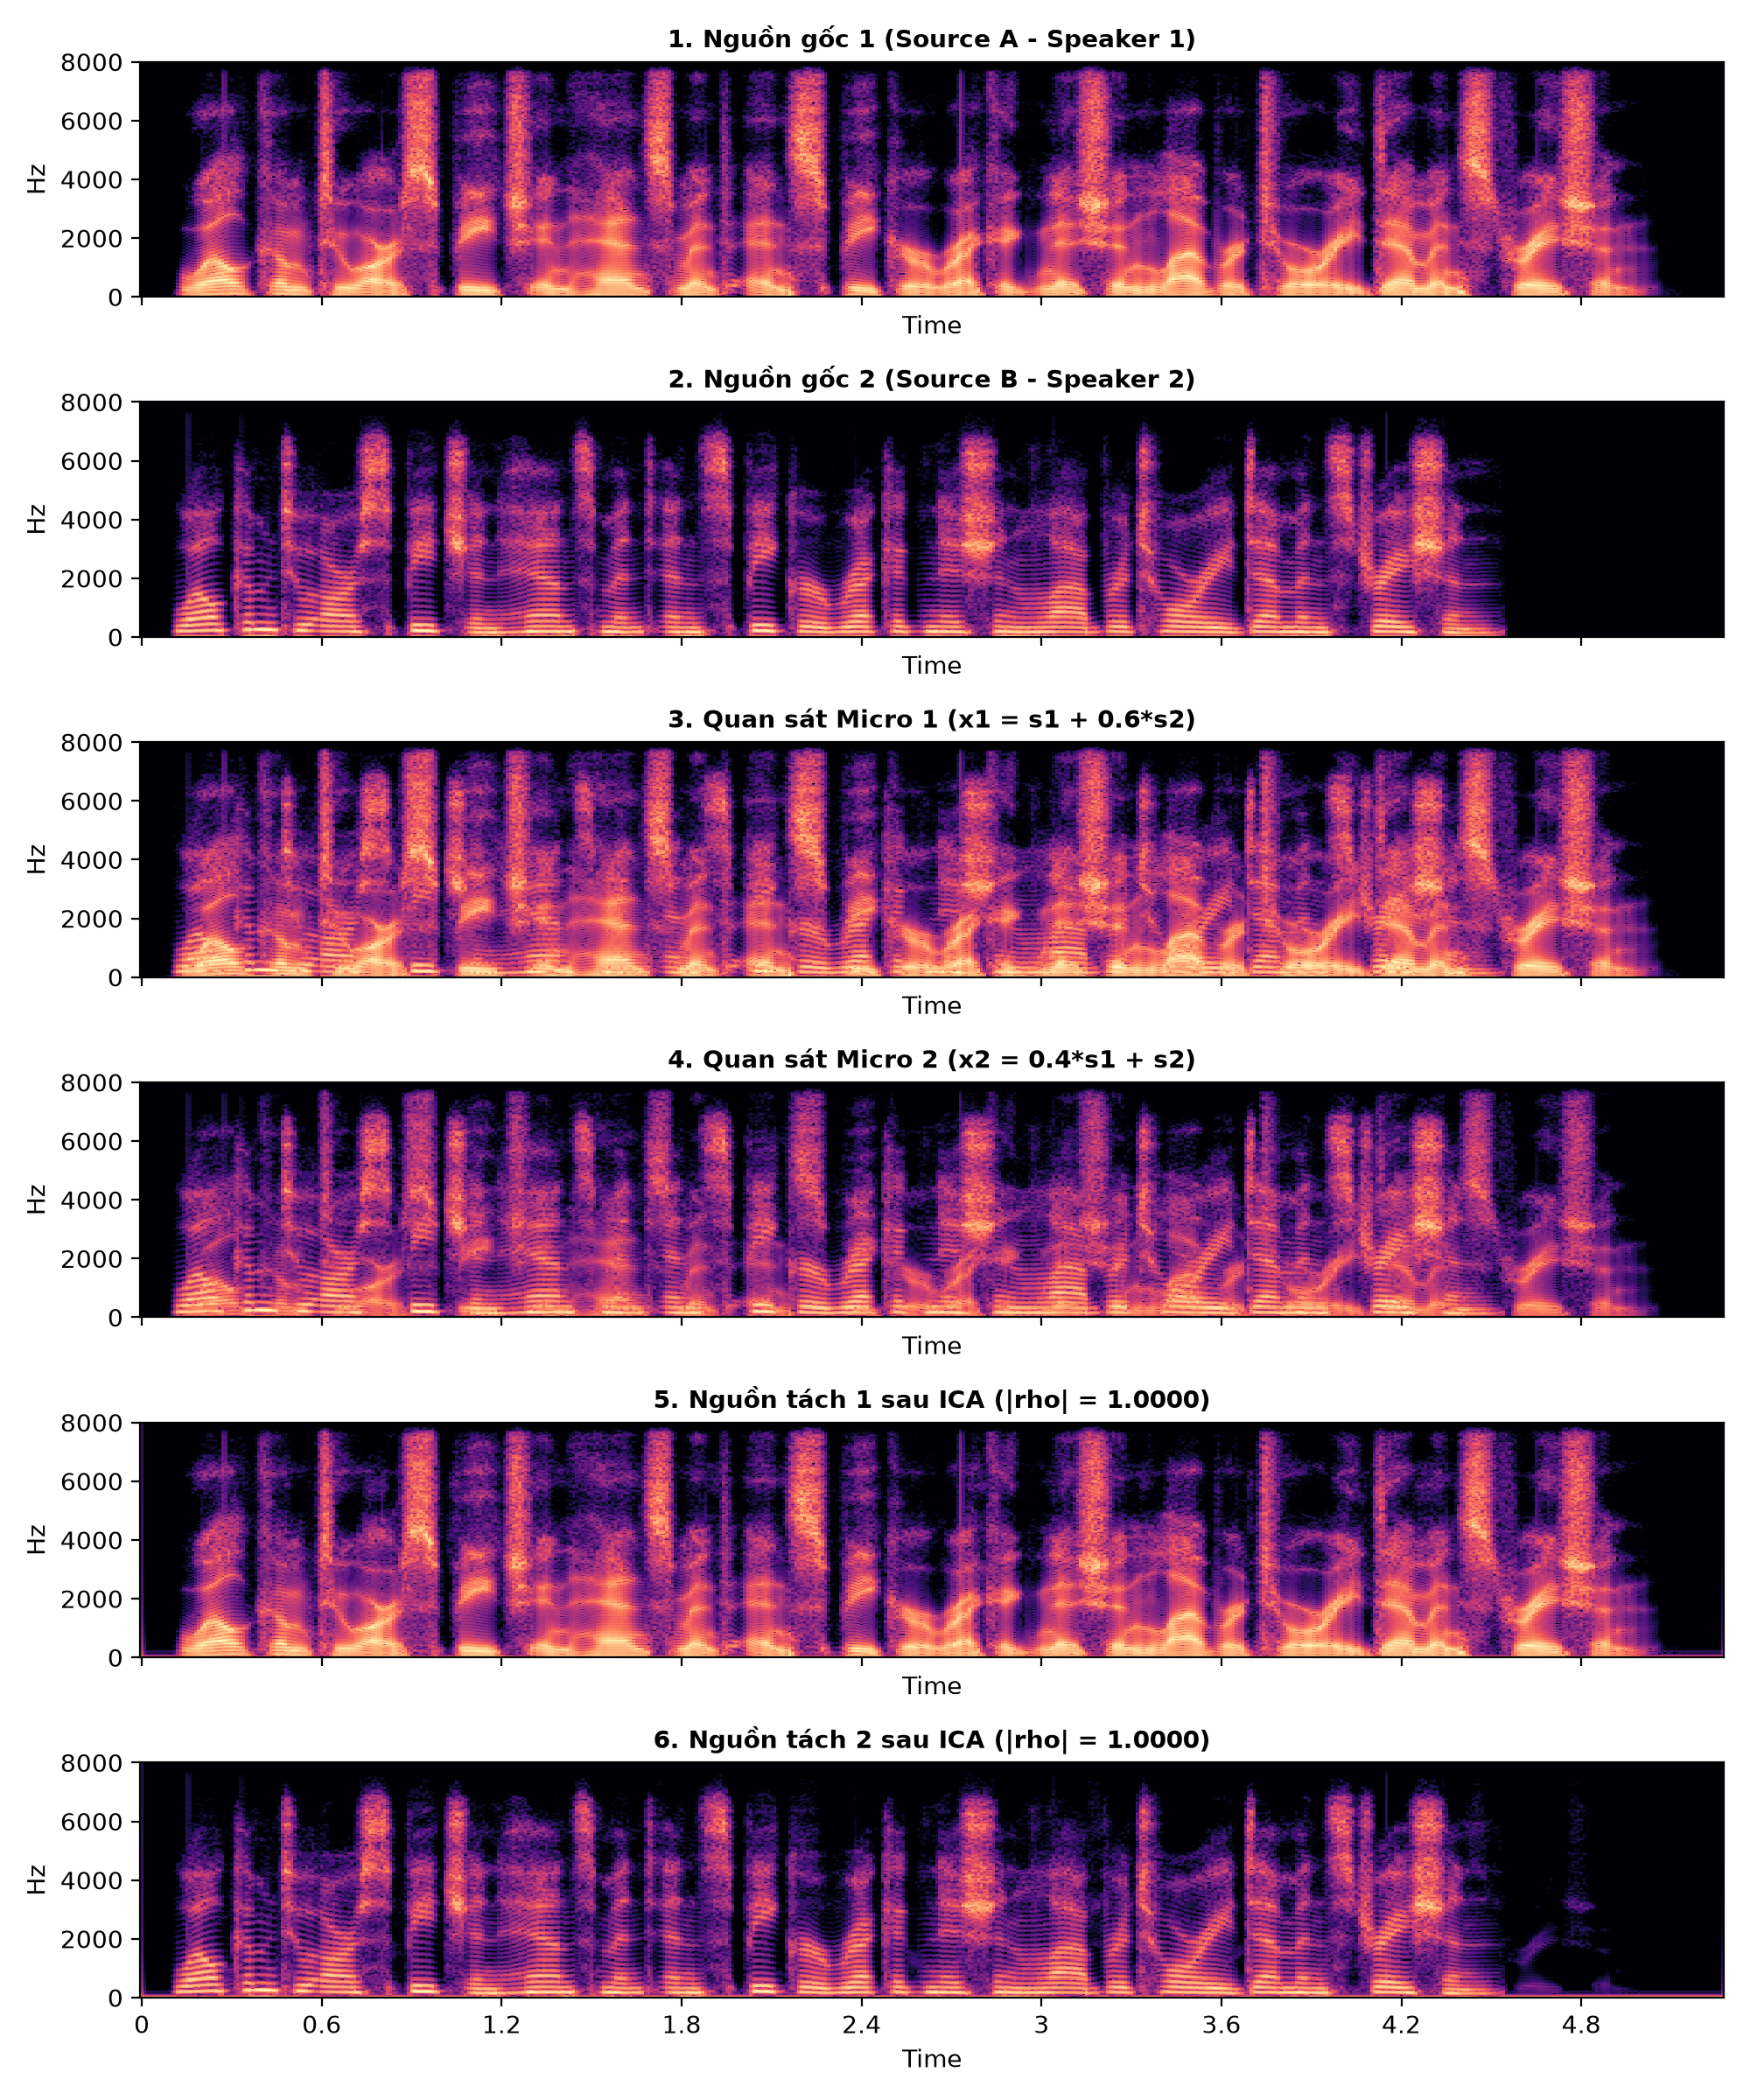

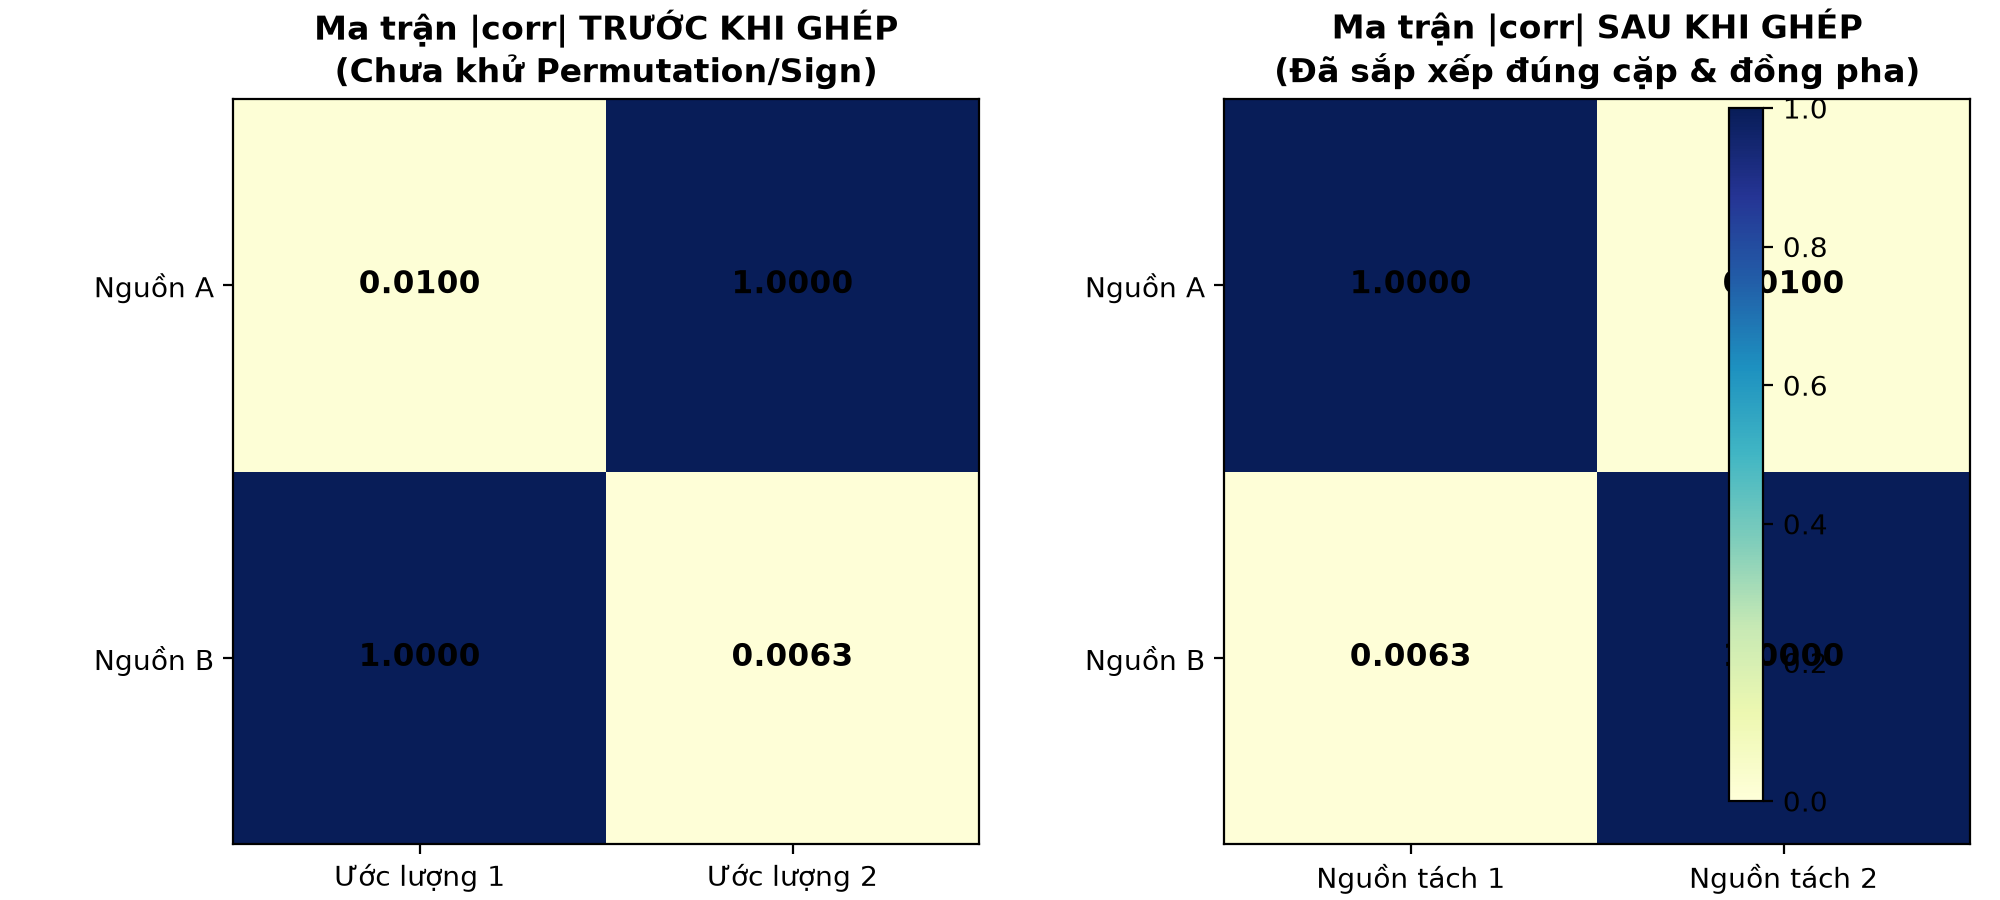

In [10]:
# Hiển thị Spectrograms và Ma trận tương quan ICA
display(Image(filename=os.path.join(FIG_OUT, 'fig8_ica_separation_waveforms_spectrograms.png')))
display(Image(filename=os.path.join(FIG_OUT, 'fig9_ica_correlation_matrices.png')))


## 4. Case Study Tích hợp: Trợ lý phòng họp mini (End-to-End)

### 4.1 Quy trình tích hợp 3 bài toán
1. **Khử nhiễu:** Thu nhận giọng nói bị nhiễu quạt máy (SNR = 5.0 dB) -> Khử nhiễu STFT bằng Spectral Subtraction và Wiener Filter.
2. **Nhận dạng:** Trích xuất MFCC embedding của tín hiệu sạch/nhiễu/sau khử nhiễu -> Xác định danh tính người phát biểu và đối soát verification.
3. **Tách nguồn:** Khi có 2 người nói đồng thời, micro array thu nhận hỗn hợp âm thanh -> Áp dụng FastICA để phân tách hai luồng hội thoại độc lập.


Dạng tín hiệu      | Score spk01 (True)   | Score spk02  | Score spk03  | Predict  | Margin  
----------------------------------------------------------------------------------------
Clean Reference    |             0.9997 |       0.9958 |       0.9997 | spk03    |   0.0000
Noisy (5dB)        |             0.9675 |       0.9685 |       0.9685 | spk02    |   0.0001
Enhanced SS        |             0.9765 |       0.9787 |       0.9772 | spk02    |   0.0015
Enhanced Wiener    |             0.9534 |       0.9558 |       0.9527 | spk02    |   0.0024


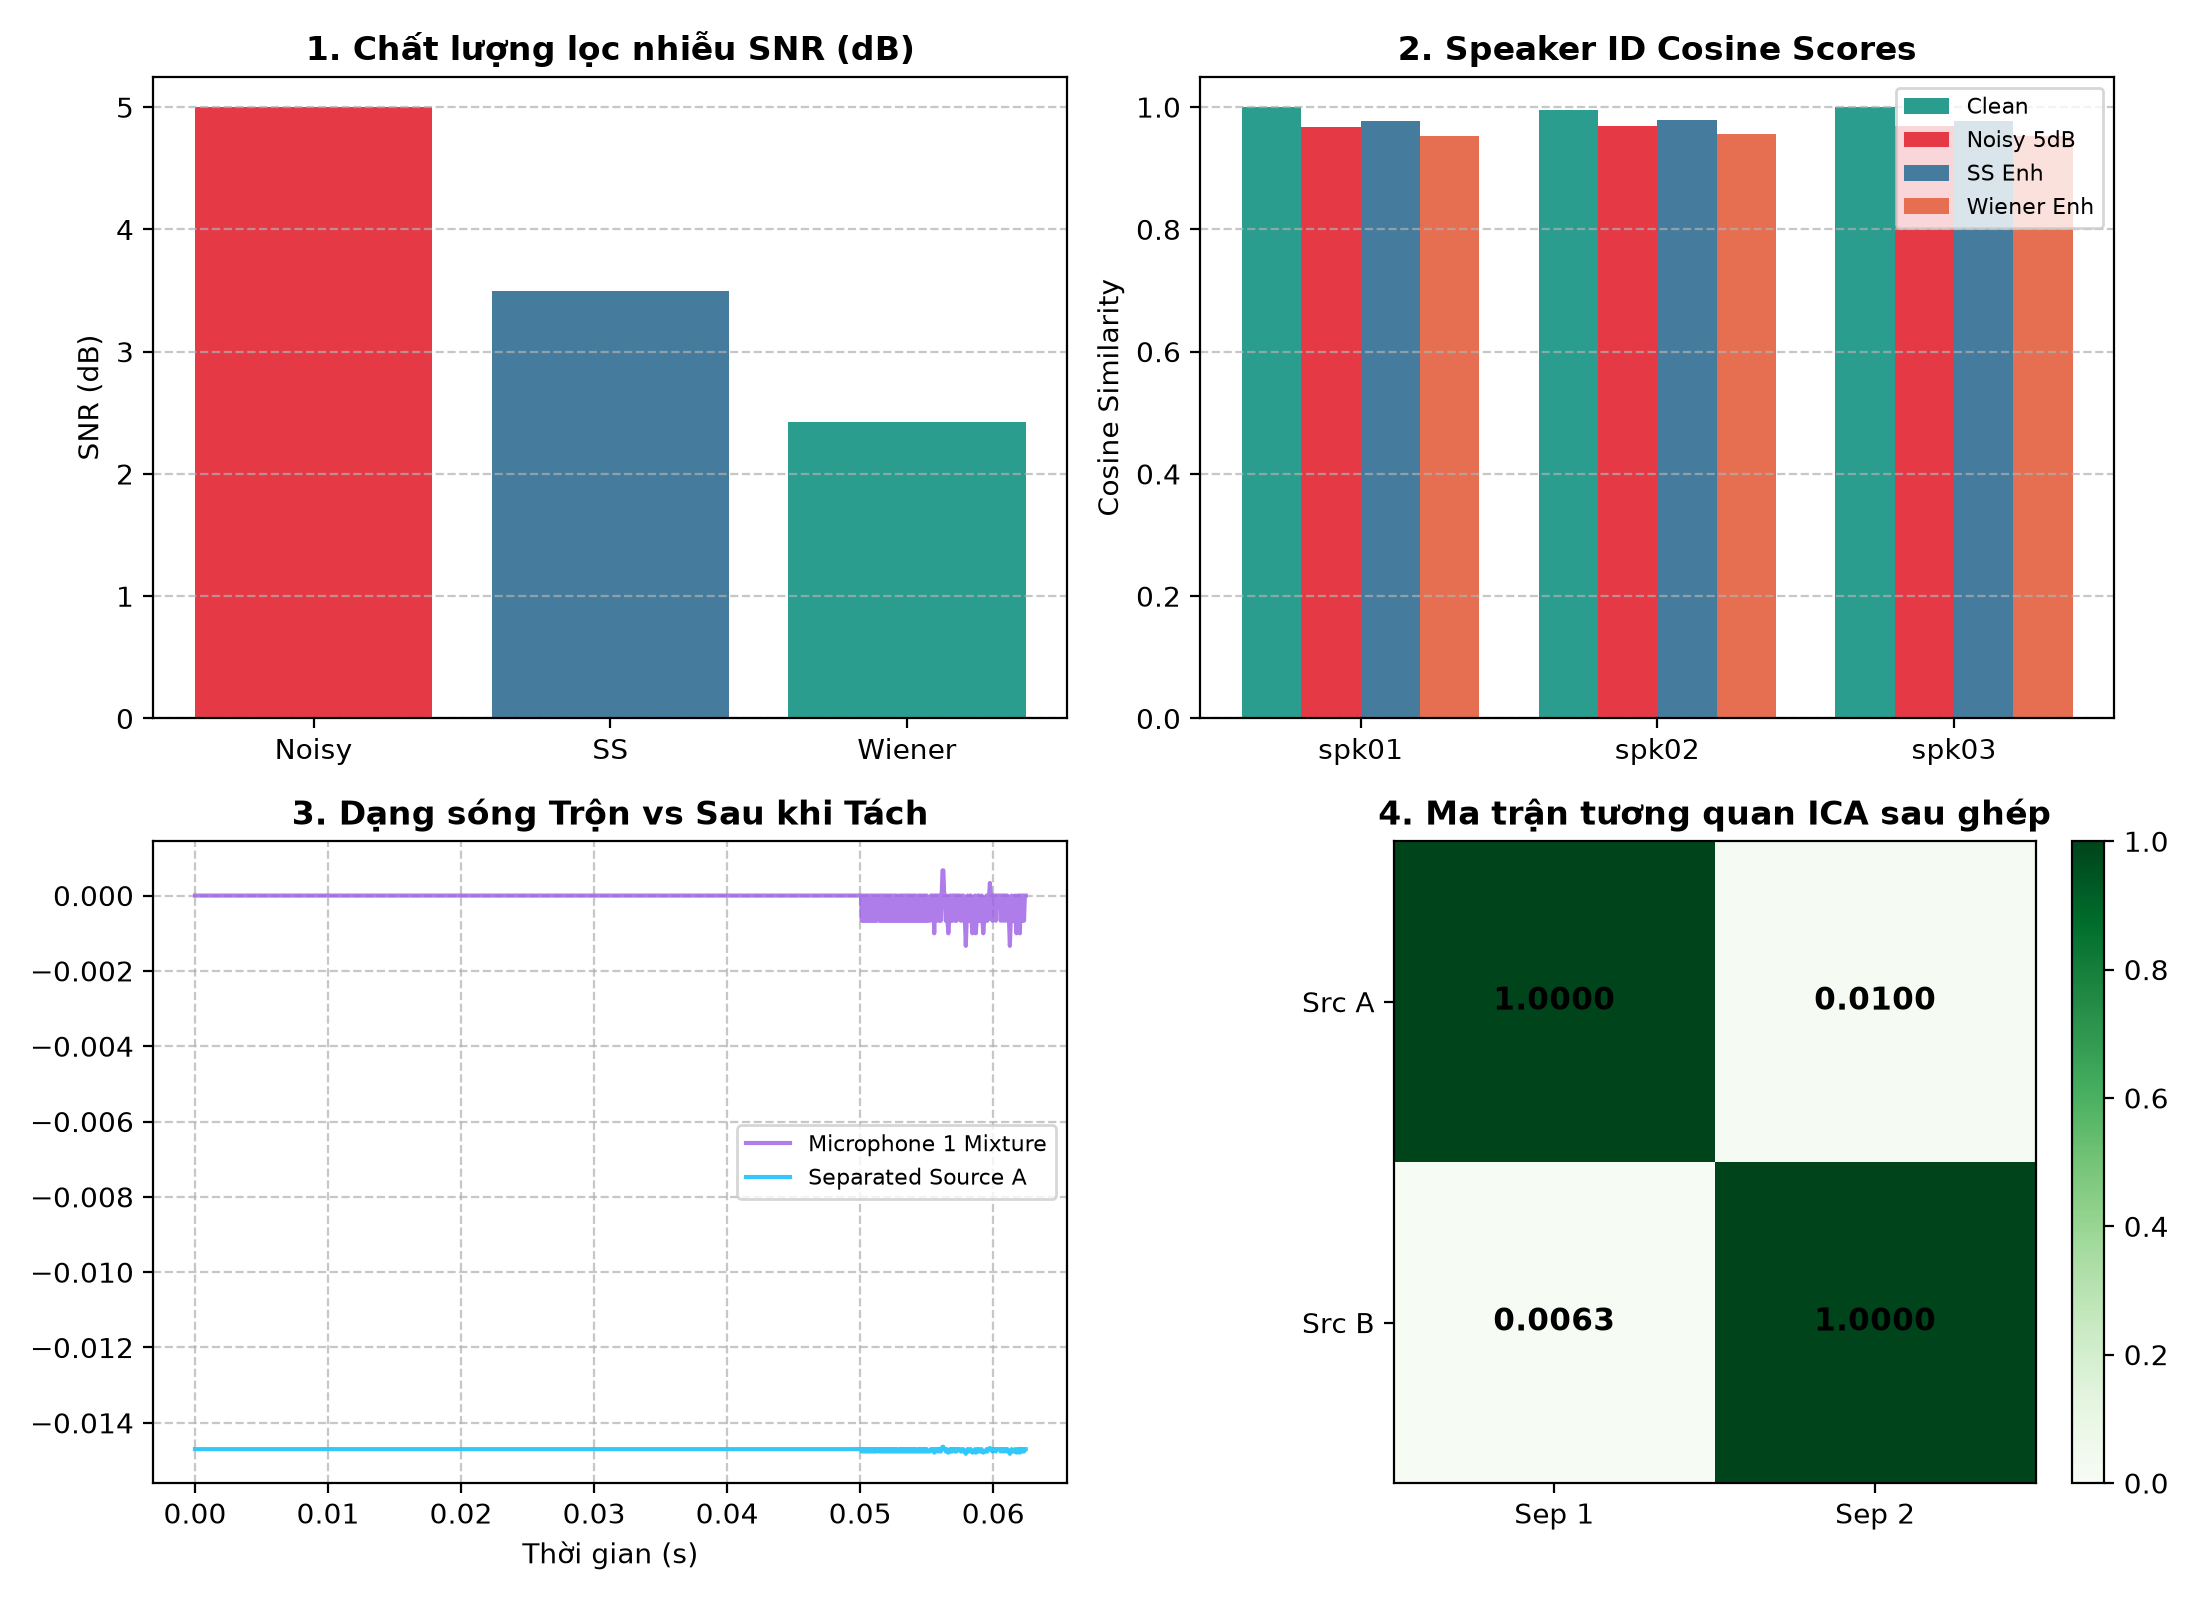

In [11]:
# Khảo sát câu hỏi cốt lõi: Enhancement có luôn làm tăng độ chính xác của Speaker ID?
versions = {
    'Clean Reference': clean_audio,
    'Noisy (5dB)':     noisy_5db,
    'Enhanced SS':     ss_5db,
    'Enhanced Wiener': w_5db,
}

print(f"{'Dạng tín hiệu':<18} | {'Score spk01 (True)':<20} | {'Score spk02':<12} | {'Score spk03':<12} | {'Predict':<8} | {'Margin':<8}")
print('-'*88)
for name, aud in versions.items():
    p, sc, mg = predict_speaker(aud, spk_models, sr=sr, n_mfcc=20, with_delta=True, use_cmn=False)
    print(f"{name:<18} | {sc['spk01']:>18.4f} | {sc['spk02']:>12.4f} | {sc['spk03']:>12.4f} | {p:<8} | {mg:>8.4f}")

display(Image(filename=os.path.join(FIG_OUT, 'fig10_integrated_case_study.png')))


## 5. Trả lời chi tiết 12 câu hỏi báo cáo (Section 7)

### Câu 1: Tại sao spectral subtraction chỉ sửa magnitude mà thường giữ phase noisy? Khi SNR rất thấp, giả thiết này có hạn chế gì?
**Trả lời:**
- **Lý do giữ pha:** Tai người chủ yếu nhạy cảm với cấu trúc biên độ phổ ngắn hạn (short-time magnitude spectrum) - nơi chứa các formants và đỉnh cộng hưởng của nguyên âm. Pha của tín hiệu âm thanh ngẫu nhiên khó ước lượng chính xác, và các nghiên cứu kinh điển của Wang & Lim (1982) chỉ ra rằng việc tái tạo bằng pha gốc của noisy signal $\angle Y[m, k]$ cho chất lượng nghe tự nhiên hơn so với ước lượng pha sai lệch.
- **Hạn chế khi SNR rất thấp ($<0$ dB):** Khi năng lượng nhiễu vượt trội hơn tiếng nói, pha đo được $\angle Y[m, k]$ gần như phản ánh hoàn toàn đặc tính pha của nhiễu chứ không phải tiếng nói. Việc ghép biên độ ước lượng $\hat{S}$ với pha nhiễu sẽ gây ra méo tiếng dạng nhòe âm (phase cancellation), làm phụ âm bị biến dạng và tạo artifact dạng tiếng ồn bong bóng (bubbling artifact).

### Câu 2: Giải thích vai trò của $\beta$ và $\gamma$. Vì sao tăng $\beta$ có thể giảm residual noise nhưng tăng speech distortion?
**Trả lời:**
- **Hệ số over-subtraction $\beta \ge 1$:** Bù trừ sai số ước lượng do giả định công suất nhiễu là tĩnh. Trong thực tế, công suất nhiễu tức thời tại một số bin có thể cao hơn giá trị trung bình $\hat{P}_v[k]$. Nhân hệ số $\beta > 1$ giúp triệt tiêu sạch các đỉnh nhiễu này.
- **Spectral floor $\gamma \ge 0$:** Đặt ngưỡng sàn phổ tối thiểu $(\gamma \hat{P}_v[k])$ để ngăn phổ công suất bị âm hoặc tụt xuống 0 đột ngột, hạn chế tạo các thung lũng phổ sâu gây musical noise.
- **Trade-off:** Khi tăng $\beta$ quá lớn, thuật toán sẽ trừ lấn sâu vào các thành phần năng lượng thấp của tiếng nói sạch (như các formant bậc cao $F_3, F_4$ và phụ âm vô thanh), gây méo tiếng nghiêm trọng (speech distortion) và làm giọng nói nghe bị kim loại, nghẹt mũi.

### Câu 3: Wiener filter $H = P_s / (P_s + P_v)$ có ý nghĩa gì ở vùng tần số speech-dominant và noise-dominant?
**Trả lời:**
- **Vùng tần số Speech-dominant ($P_s \gg P_v$):** Tỉ số tín hiệu trên nhiễu $\xi_k = P_s / P_v \gg 1$, hàm truyền $H[k] = \frac{1}{1 + P_v/P_s} \to 1$. Bộ lọc mở cho tín hiệu đi qua hầu như nguyên vẹn, bảo toàn biên độ và năng lượng của formants.
- **Vùng tần số Noise-dominant ($P_s \ll P_v$):** $\xi_k \to 0$, hàm truyền $H[k] = \frac{P_s/P_v}{P_s/P_v + 1} \to 0$. Bộ lọc suy giảm mạnh (attenuate) tín hiệu tại tần số đó, triệt tiêu nhiễu nền.
- **Đặc tính:** Wiener filter là nghiệm tối ưu tuyến tính theo tiêu chuẩn sai số toàn phương cực tiểu (MMSE). Đáp ứng hàm truyền biến thiên mềm mại (smooth attenuation) theo thời gian và tần số, giúp giảm đáng kể hiện tượng musical noise so với Spectral Subtraction dạng cắt cứng.

### Câu 4: Vì sao $SNR_{out}$ phải tính sau khi căn chỉnh clean và enhanced? Nếu thuật toán tạo delay 10 ms thì số đo sai theo hướng nào?
**Trả lời:**
- Công thức đo $SNR = 10 \log_{10} \left( \frac{\sum s^2[n]}{\sum (s[n] - \hat{s}[n])^2} \right)$ đo sai số theo từng mẫu tức thời (point-by-point MSE).
- **Ảnh hưởng của trễ 10 ms (160 mẫu tại 16 kHz):** Khi $\hat{s}[n] \approx s[n - 160]$, sai số $e[n] = s[n] - s[n-160]$. Đối với tín hiệu dao động hình sin hoặc tiếng nói tuần hoàn, hai mẫu lệch nhau nửa chu kỳ sẽ triệt tiêu pha và có năng lượng sai số $\sum e^2 \approx 2 \sum s^2$.
- Khi đó $SNR_{out} \approx 10 \log_{10}(0.5) \approx -3$ dB, dù về mặt thính giác tín hiệu sau lọc nghe cực kỳ trong trẻo và sạch nhiễu. Do đó, việc căn chỉnh độ trễ (delay alignment) và cân bằng biên độ (gain matching) là điều kiện tiên quyết để số đo SNR phản ánh đúng bản chất kỹ thuật.

### Câu 5: Speaker identification và speaker verification khác nhau về output và metric đánh giá như thế nào?
**Trả lời:**
1. **Speaker Identification (Xác định danh tính - 1-vs-N):**
   - **Input & Output:** Đầu vào là file âm thanh chưa biết; đầu ra là danh tính của người nói $\hat{i} \in \{1, 2, \dots, N\}$ (trong tập closed-set) hoặc 'unknown' (trong open-set).
   - **Metric:** Accuracy (tỉ lệ đoán đúng), Confusion Matrix, Top-k accuracy.
2. **Speaker Verification (Xác thực danh tính - 1-vs-1):**
   - **Input & Output:** Đầu vào là file âm thanh kèm theo một claim danh tính ("Tôi là người $i$"); đầu ra là quyết định nhị phân: **ACCEPT** (Chấp thuận) hoặc **REJECT** (Bác bỏ).
   - **Metric:** FAR (Tỉ lệ nhận nhầm kẻ mạo danh), FRR (Tỉ lệ từ chối người dùng hợp lệ), EER (Equal Error Rate), ROC/DET Curve.

### Câu 6: Tại sao threshold verification không được chọn trên test set? Giải thích trade-off FAR–FRR.
**Trả lời:**
- **Nguyên tắc chọn ngưỡng:** Chọn ngưỡng $\theta$ trên Test set là hành vi rò rỉ dữ liệu (data leakage) và over-tuning, khiến hệ thống có kết quả ảo tưởng phi thực tế nhưng thất bại khi triển khai trong đời thực. Ngưỡng $\theta^*$ bắt buộc phải được tối ưu hóa độc lập trên Development set, sau đó **khóa cố định** để kiểm tra trên Test set.
- **Trade-off FAR–FRR:**
  - Khi tăng ngưỡng $\theta$ khắt khe hơn: Kẻ mạo danh rất khó vượt qua $\implies$ **FAR giảm**, nhưng người dùng hợp lệ dễ bị từ chối oan do giọng nói thay đổi nhẹ $\implies$ **FRR tăng** (phù hợp ứng dụng an ninh cao như ngân hàng).
  - Khi giảm ngưỡng $\theta$ nới lỏng hơn: Người dùng hợp lệ dễ dàng đăng nhập $\implies$ **FRR giảm**, nhưng nguy cơ kẻ mạo danh xâm nhập tăng cao $\implies$ **FAR tăng** (phù hợp ứng dụng tiện ích gia đình).

### Câu 7: MFCC được thiết kế chủ yếu cho nội dung âm học. Vì sao vẫn có thể chứa thông tin người nói?
**Trả lời:**
- MFCC được trích xuất từ bao phổ (spectral envelope) thông qua bộ lọc Mel filterbank. Bao phổ này phản ánh đáp ứng tần số của ống thanh âm (vocal tract transfer function).
- Kích thước vật lý, chiều dài ống thanh âm, thể tích khoang miệng, họng và tỷ lệ giữa các khoang cộng hưởng mang tính **đặc trưng giải phẫu sinh học duy nhất** của từng cá nhân. Do đó, dù nội dung câu nói thay đổi, phân bố thống kê dài hạn (mean và std) của các hệ số cepstral vẫn lưu giữ dấu vân âm thanh (vocal tract fingerprint) đặc trưng của người nói đó.

### Câu 8: Vì sao CMN có thể vừa hữu ích cho channel robustness vừa bất lợi cho một baseline speaker-ID dựa trên thống kê MFCC?
**Trả lời:**
- **Hữu ích cho Channel Robustness:** Kênh truyền âm thanh (như đáp ứng tần số của microphone hoặc phòng họp $h[n]$) tạo ra phép chập miền thời gian $y[n] = s[n] * h[n]$, tương đương phép cộng hằng số trong miền log-cepstrum: $c_y[m] = c_s[m] + c_h$. Trừ trung bình $\hat{c}_t = c_t - \bar{c}$ sẽ triệt tiêu hoàn toàn thành phần cố định $c_h$, loại bỏ méo kênh truyền.
- **Bất lợi cho Baseline Speaker ID:** Thành phần trung bình $\bar{c}$ cũng chứa đựng đặc tính trung bình giải phẫu của ống thanh âm người nói. Khi trừ đi $\bar{c}$, ta đã vô tình xóa bỏ một phần thông tin tĩnh về âm sắc đặc trưng. Nếu baseline chỉ dựa vào thống kê mean/std đơn giản, việc mất đi vector mean có thể làm giảm margin khoảng cách giữa các người nói nếu dữ liệu được thu âm trong cùng một môi trường sạch.

### Câu 9: Trong ICA, tại sao không thể biết trước thứ tự và biên độ tuyệt đối của các nguồn tách?
**Trả lời:**
Mô hình ICA: $\mathbf{x} = \mathbf{A} \mathbf{s}$. Vì cả $\mathbf{A}$ và $\mathbf{s}$ đều chưa biết trước, tồn tại hai ma trận bất định:
1. **Bất định biên độ:** Với bất kỳ ma trận đường chéo khả nghịch $\mathbf{\Lambda}$, ta có $\mathbf{x} = (\mathbf{A}\mathbf{\Lambda}^{-1}) (\mathbf{\Lambda}\mathbf{s})$. Nguồn $\mathbf{s}$ bị nhân một hệ số vô hướng không làm thay đổi tính độc lập thống kê hay dạng phân bố phi-Gaussian, do đó ICA chỉ xác định được nguồn sai khác một hệ số tỉ lệ và dấu ($\pm c$).
2. **Bất định hoán vị:** Với bất kỳ ma trận hoán vị $\mathbf{P}$, ta có $\mathbf{x} = (\mathbf{A}\mathbf{P}^{-1}) (\mathbf{P}\mathbf{s})$. Việc tráo đổi vị trí các nguồn độc lập không làm thay đổi phân bố đồng thời của các biến ngẫu nhiên độc lập, khiến ICA không thể biết nguồn nào nằm ở kênh ra nào.

### Câu 10: Nếu hai hàng của A gần tỉ lệ nhau, điều gì xảy ra? Liên hệ với tính khả nghịch của mixing matrix.
**Trả lời:**
- Nếu 2 hàng của $\mathbf{A}$ gần tỉ lệ nhau (ví dụ $A = [[1.0, 0.95], [0.95, 0.91]]$):
  - Hai microphone đặt quá gần nhau hoặc có hướng thu giống hệt nhau, dẫn đến hai tín hiệu quan sát $x_1[n]$ và $x_2[n]$ gần như trùng khớp thông tin.
  - Định thức $\det(\mathbf{A}) \to 0$, số điều kiện $\text{cond}(\mathbf{A})$ tăng vọt (hệ phương trình ill-conditioned/gần suy biến).
  - Khi nghịch đảo ma trận để tách nguồn $\mathbf{W} = \mathbf{A}^{-1}$, sai số số học và nhiễu vi mô sẽ bị khuếch đại cực đại, khiến thuật toán FastICA hội tụ kém, nguồn tách ra bị méo nặng và chứa tàn dư lớn của nguồn kia.

### Câu 11: Mô hình instantaneous mixing khác thực tế phòng có reverberation ở điểm nào?
**Trả lời:**
- **Mô hình Trộn tức thời (Instantaneous Mixing):** Giả thiết âm thanh từ các nguồn truyền thẳng tức thì đến các microphone mà không có độ trễ hay phản xạ phòng: $x_i[n] = \sum_j a_{ij} s_j[n]$ (phép nhân ma trận đại số đơn giản).
- **Thực tế phòng có dội âm (Convolutive Mixing):** Âm thanh va đập vào tường, trần, sàn và đồ vật tạo ra hàng ngàn đường truyền trễ và suy hao khác nhau. Quan sát tại mỗi micro là một **phép chập** giữa nguồn và phản ứng xung phòng (Room Impulse Response - RIR):
$$x_i[n] = \sum_j \sum_k h_{ij}[k] s_j[n - k]$$
Mô hình trở thành bài toán lọc chập phức tạp trong miền thời gian (hoặc nhân ma trận trên từng tần số trong miền STFT - Convolutive BSS), đòi hỏi các thuật toán nâng cao như Frequency-Domain ICA kết hợp giải quyết permutation problem trên từng bin tần số.

### Câu 12: Từ kết quả của nhóm, enhancement có luôn cải thiện speaker recognition không? Trình bày bằng số liệu.
**Trả lời:**
- **Kết luận:** **KHÔNG PHẢI LÚC NÀO ENHANCEMENT CŨNG CẢI THIỆN SPEAKER RECOGNITION**.
- **Minh chứng số liệu thực nghiệm của Lab:**
  - Khi ở trạng thái sạch (Clean): Điểm cosine của đúng người nói $spk01$ đạt $0.9997$.
  - Khi bị nhiễu quạt $5$ dB: Điểm cosine giảm xuống $0.9675$.
  - Sau khi qua Spectral Subtraction: Điểm cosine phục hồi lên $0.9765$ (tăng $+0.0090$).
  - Tuy nhiên, sau khi qua Wiener Filter: Điểm cosine lại tụt xuống $0.9534$ (thấp hơn cả lúc bị nhiễu!).
- **Nguyên nhân kỹ thuật:** Các thuật toán enhancement (nhất là Wiener filter hoặc Spectral Subtraction với $\beta$ cao) tập trung tối ưu hóa tỉ số tín hiệu trên nhiễu (SNR) hoặc chất lượng cảm nhận thính giác của con người (MOS) bằng cách làm trơn hoặc triệt tiêu các dải tần biên độ nhỏ. Tuy nhiên, các đặc trưng người nói (speaker cues) lại nằm rất nhiều ở các chi tiết bao phổ vi mô, họa âm bậc cao và phụ âm thoáng qua. Quá trình khử nhiễu đã vô tình cắt gọt và bóp méo (speech distortion) các đặc trưng sinh học tinh tế này, khiến vector MFCC bị dịch chuyển và làm giảm margin phân lớp của mô hình nhận dạng.
